# Exercise 2.4.iv

A simplified Zhou model:
- n=2
- u ~ U(0,1)
- Firm 1 is free to visit. Firm 2 costs s in (0, 1/8) to visit
- Consumers observe u and p upon visiting

In [2]:
import numpy as np
from scipy.optimize import fsolve

In [3]:
# def profits(pt1, pt2, p2, s):
#     """Profits given actual prices (pt1, pt2) and the expected price p2."""
#     x = 1 - np.sqrt(2 * s) - p2 + pt1           # search firm 2 iff u1 < x
#     back = x**2 / 2 + x * (pt2 - pt1)           # search, then return to firm 1
#     return pt1 * (1 - x + back), pt2 * (x - back)


# def focs(p, s, h=1e-6):
#     """Each firm's marginal profit in its own price, at pt = p (rational expectations)."""
#     p1, p2 = p
#     d1 = (profits(p1 + h, p2, p2, s)[0] - profits(p1 - h, p2, p2, s)[0]) / (2 * h)
#     d2 = (profits(p1, p2 + h, p2, s)[1] - profits(p1, p2 - h, p2, s)[1]) / (2 * h)
#     return [d1, d2]


# def solve_equilibrium(s, guess=(0.5, 0.5)):
#     return fsolve(focs, guess, args=(s,))


def profits(pt1, pt2, p2, s):
    """Profits given actual prices (pt1, pt2) and the expected price p2."""
    z = 1 - np.sqrt(2 * s) - p2                 # z_2 = a - p_2: search firm 2 iff u1 - pt1 < z
    back1 = z**2 / 2 + pt2 * z                  # search, then return to firm 1
    back2 = z**2 / 2 + pt1 * z                  # buy at firm 2 after comparing with firm 1
    return pt1 * (1 - pt1 - z + back1), pt2 * ((pt1 + z) * (1 - pt2 - z) + back2)


def focs(p, s, h=1e-6):
    """Each firm's marginal profit in its own price, at pt = p (rational expectations)."""
    p1, p2 = p
    d1 = (profits(p1 + h, p2, p2, s)[0] - profits(p1 - h, p2, p2, s)[0]) / (2 * h)
    d2 = (profits(p1, p2 + h, p2, s)[1] - profits(p1, p2 - h, p2, s)[1]) / (2 * h)
    return [d1, d2]


def solve_equilibrium(s, guess=(0.45, 0.45)):
    return fsolve(focs, guess, args=(s,))

In [4]:
for s in [1/8*0.01, 1/8*0.1, 1/8*0.3, 1/8*0.5, 1/8*0.8, 1/8]:
    p1, p2 = solve_equilibrium(s)
    print(f"s = {s:.3f}:  p1 = {p1:.4f},  p2 = {p2:.4f}")

s = 0.001:  p1 = 0.4187,  p2 = 0.4275
s = 0.013:  p1 = 0.4318,  p2 = 0.4541
s = 0.037:  p1 = 0.4506,  p2 = 0.4780
s = 0.062:  p1 = 0.4663,  p2 = 0.4902
s = 0.100:  p1 = 0.4872,  p2 = 0.4986
s = 0.125:  p1 = 0.5000,  p2 = 0.5000


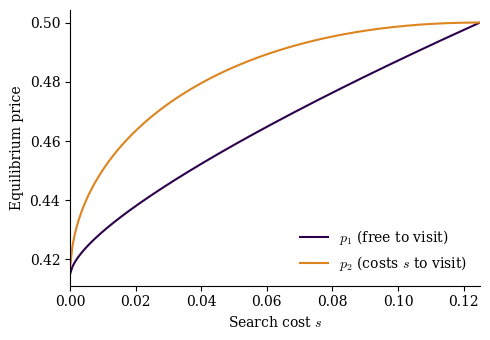

In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'CMU Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'axes.unicode_minus': False,
})

STYLE = {'p1': dict(color='#2D004B', ls='-'),
         'p2': dict(color='#DD841F', ls='-')}

s_grid = np.linspace(1e-4, 1/8, 200)
eq = []
guess = (0.45, 0.45)
for s in s_grid:
    guess = solve_equilibrium(s, guess)   # warm start from previous s
    eq.append(guess)
eq = np.array(eq)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(s_grid, eq[:, 0], label=r"$p_1$ (free to visit)", **STYLE['p1'])
ax.plot(s_grid, eq[:, 1], label=r"$p_2$ (costs $s$ to visit)", **STYLE['p2'])

ax.set_xlabel(r"Search cost $s$")
ax.set_ylabel("Equilibrium price")

ax.set_xlim(0, 1/8)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("res/zhou_prices.pdf")
plt.show()